# Inventory Prioritization

I rank categories, stores and products by historical units sold. This gives a starting point for reviewing stock availability.

## 1. Load sales

Sum daily sales for each product-store row.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

sales = pd.read_csv("data/raw/sales_train_validation.csv")
day_columns = [column for column in sales.columns if column.startswith("d_")]
sales["total_units"] = sales[day_columns].sum(axis=1)
print(f"Rows: {sales.shape[0]:,}")
print(f"Total historical units: {sales['total_units'].sum():,.0f}")

Rows: 30,490
Total historical units: 65,695,409


## 2. Categories

Compare total units and each category’s share of sales. A larger total can reflect more products as well as higher sales per product.

In [2]:
category_summary = (
    sales.groupby("cat_id", as_index=False)["total_units"]
    .sum()
    .sort_values("total_units", ascending=False)
)
category_summary["share_pct"] = category_summary["total_units"] / category_summary["total_units"].sum() * 100
category_summary

,cat_id,total_units,share_pct
0,FOODS,45089939,68.634840
2,HOUSEHOLD,14480670,22.042134
1,HOBBIES,6124800,9.323026


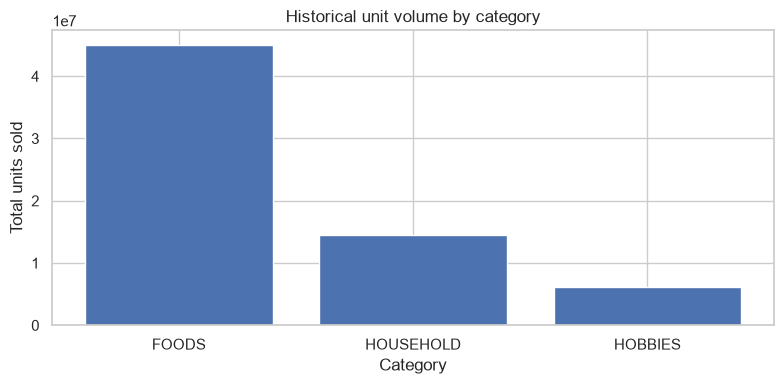

In [3]:
plt.figure(figsize=(8, 4))
plt.bar(category_summary["cat_id"], category_summary["total_units"])
plt.title("Historical unit volume by category")
plt.xlabel("Category")
plt.ylabel("Total units sold")
plt.tight_layout()
plt.show()

## 3. Stores

Compare sales volume across stores. Lead times, delivery schedules and storage space are also needed to choose replenishment rules.

In [4]:
store_summary = (
    sales.groupby(["state_id", "store_id"], as_index=False)["total_units"]
    .sum()
    .sort_values("total_units", ascending=False)
)
store_summary["share_pct"] = store_summary["total_units"] / store_summary["total_units"].sum() * 100
store_summary

,state_id,store_id,total_units,share_pct
2,CA,CA_3,11188180,17.030383
0,CA,CA_1,7698216,11.718043
5,TX,TX_2,7214384,10.981565
8,WI,WI_2,6544012,9.961141
9,WI,WI_3,6427782,9.784218
6,TX,TX_3,6089330,9.269034
1,CA,CA_2,5685475,8.654296
4,TX,TX_1,5595292,8.517021
7,WI,WI_1,5149062,7.837781
3,CA,CA_4,4103676,6.246519


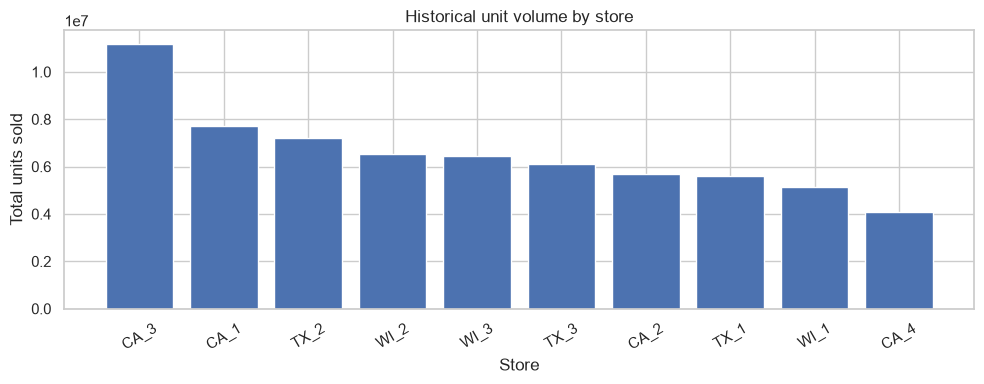

In [5]:
plt.figure(figsize=(10, 4))
plt.bar(store_summary["store_id"], store_summary["total_units"])
plt.title("Historical unit volume by store")
plt.xlabel("Store")
plt.ylabel("Total units sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. ABC groups

Sort products by total units sold across all stores. A includes products whose cumulative share is at most 80%; B extends to 95%; C contains the rest. Boundary-crossing products enter the next group, so shares are approximate. These groups describe unit volume rather than revenue or profit.

In [6]:
product_summary = (
    sales.groupby("item_id", as_index=False)["total_units"]
    .sum()
    .sort_values("total_units", ascending=False)
)
product_summary["cumulative_share"] = product_summary["total_units"].cumsum() / product_summary["total_units"].sum()
product_summary["abc_class"] = product_summary["cumulative_share"].apply(
    lambda share: "A" if share <= 0.80 else ("B" if share <= 0.95 else "C")
 )
product_summary.head(10)

,item_id,total_units,cumulative_share,abc_class
702,FOODS_3_090,1002529,0.015260,A
1198,FOODS_3_586,920242,0.029268,A
864,FOODS_3_252,565299,0.037873,A
1167,FOODS_3_555,491287,0.045351,A
1325,FOODS_3_714,396172,0.051382,A
1199,FOODS_3_587,396119,0.057411,A
1306,FOODS_3_694,390001,0.063348,A
838,FOODS_3_226,363082,0.068874,A
814,FOODS_3_202,295689,0.073375,A
1334,FOODS_3_723,284333,0.077703,A


In [7]:
abc_summary = (
    product_summary.groupby("abc_class", as_index=False)
    .agg(products=("item_id", "count"), units=("total_units", "sum"))
)
abc_summary["unit_share_pct"] = abc_summary["units"] / abc_summary["units"].sum() * 100
abc_summary = abc_summary.set_index("abc_class").reindex(["A", "B", "C"]).reset_index()
abc_summary

,abc_class,products,units,unit_share_pct
0,A,1033,52544890,79.982591
1,B,990,9860688,15.009706
2,C,1026,3289831,5.007703


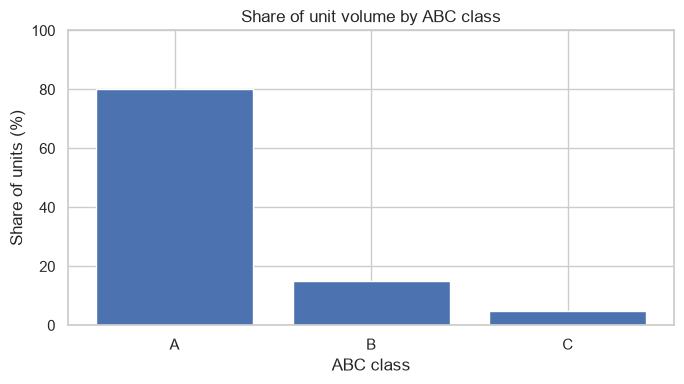

In [8]:
plt.figure(figsize=(7, 4))
plt.bar(abc_summary["abc_class"], abc_summary["unit_share_pct"])
plt.title("Share of unit volume by ABC class")
plt.xlabel("ABC class")
plt.ylabel("Share of units (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 5. Using the groups

A-items account for most recorded units and are a useful starting point for stock checks. The ranking combines all stores and the full sales history; repeat it with recent store-level data before applying it locally. Low-volume items can still matter because of margin, shelf life or customer needs.